In [2]:
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis
from sklearn.linear_model import LinearRegression
import time
import matplotlib.pyplot as plt
import seaborn as sns

### First create one point hpi dataframe

In [3]:
def build_features_from_hpi_dataframe(df_hpi, year_column='Year', min_year=2015):
    """
    Aplica transformaciones estadísticas a cada columna (país) del DataFrame HPI.

    Parameters:
    - df_hpi: DataFrame con columnas de países y filas de años
    - year_column: nombre de la columna que contiene los años
    - min_year: año mínimo para filtrar los datos

    Returns:
    - DataFrame con una fila por país y columnas con estadísticas
    """
    start_time = time.time()
    feature_rows = []

    # Filtrar por año mínimo
    df_hpi = df_hpi[df_hpi[year_column] >= min_year].copy()
    df_hpi = df_hpi.ffill().bfill()

    # Extraer años como variable independiente
    years = df_hpi[year_column].values.reshape(-1, 1)

    # Iterar sobre cada país (columna)
    for country in df_hpi.columns:
        if country == year_column:
            continue

        series = df_hpi[country].dropna().values
        valid_years = years[:len(series)]

        if len(series) < 2:
            continue

        features = {"Country": country}
        features[f"mean"] = np.mean(series)
        features[f"median"] = np.median(series)
        features[f"std"] = np.std(series)
        features[f"cv"] = np.std(series) / np.mean(series) if np.mean(series) != 0 else 0
        features[f"min"] = np.min(series)
        features[f"max"] = np.max(series)
        features[f"last"] = series[-1]
        features[f"growth"] = (series[-1] - series[0]) / series[0] if series[0] != 0 else 0

        if np.std(series) < 1e-8:
            features[f"skew"] = 0
            features[f"kurtosis"] = 0
        else:
            features[f"skew"] = skew(series)
            features[f"kurtosis"] = kurtosis(series)

        try:
            model = LinearRegression().fit(valid_years, series)
            features[f"trend"] = model.coef_[0]
        except:
            features[f"trend"] = np.nan

        feature_rows.append(features)

    result_df = pd.DataFrame(feature_rows)
    end_time = time.time()
    print(f"Time taken to compute features: {round(end_time - start_time, 2)} sec.")
    return result_df


In [4]:
hpi_df = pd.read_parquet('../data/clean_hpi.parquet')

In [5]:
hpi_df

,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,...,Slovenia,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom
0,2010,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,99.9975,100.0025,100.0000,...,99.9975,100.0000,99.9975,100.0025,100.0025,100.0000,100.0000,100.0000,100.0000,100.0000
1,2011,97.8450,104.2250,103.5825,119.0225,94.4900,105.7500,112.2300,104.1175,107.8900,...,102.7150,103.5900,105.2275,92.3550,102.5800,107.5100,104.2625,108.8000,97.2400,98.5450
2,2012,97.5325,117.1325,106.0150,133.0600,92.6900,110.6150,124.0250,103.4225,118.7925,...,95.6325,108.4075,108.2500,78.7075,103.8650,113.7225,107.6325,120.6750,101.8200,98.9200
3,2013,103.9925,122.5900,107.5900,145.3175,90.6500,112.7600,136.5175,109.5550,130.0650,...,90.6200,115.4075,107.8000,71.5250,109.2225,118.3000,115.9925,134.4625,111.8300,101.4550
4,2014,113.4075,126.7900,107.2250,155.3575,91.9475,118.8625,154.7200,112.3775,140.7525,...,84.6400,123.9875,109.4325,71.7450,119.5200,121.4650,127.0725,151.2500,118.8800,109.6025
5,2015,123.6450,132.0575,109.1675,156.1650,94.5100,128.4275,174.9375,108.1225,152.9325,...,85.3200,131.7975,113.0825,74.3200,135.2000,124.0775,135.9950,175.0850,125.1800,116.1250
6,2016,130.4450,141.7575,111.7175,151.9450,101.1475,148.6600,186.4325,115.2450,167.4825,...,88.0950,138.2250,116.0900,77.7550,146.3425,124.3200,142.4050,197.4625,131.8825,124.2700
7,2017,141.3350,147.0825,115.6650,149.0200,109.9125,172.2950,201.6525,123.2850,178.5650,...,95.3750,143.9375,117.5950,82.5700,156.0625,125.4250,146.4775,218.8125,139.6050,129.9250
8,2018,139.3050,157.2350,119.1575,149.8125,117.1525,178.2375,221.8375,129.8275,188.2425,...,103.7050,148.9600,120.2225,88.1275,154.5975,129.1550,153.9000,235.9525,147.3475,134.0400
9,2019,133.6400,163.4250,123.6175,155.0550,124.2050,179.4000,240.5325,137.5800,198.3700,...,110.6525,152.6875,121.9325,92.6875,158.4350,133.9900,155.0950,247.2950,153.1450,135.3700


In [6]:
one_point_hpi = build_features_from_hpi_dataframe(hpi_df)

Time taken to compute features: 0.11 sec.


In [7]:
one_point_hpi

,Country,mean,median,std,cv,min,max,last,growth,skew,kurtosis,trend
0,Australia,152.48125,141.09375,22.944956,0.150477,123.6450,192.5275,192.5275,0.557099,0.466679,-1.310874,7.462288
1,Austria,174.72725,169.17125,29.471087,0.168669,132.0575,215.6150,207.6200,0.572194,0.092005,-1.503613,9.946773
2,Belgium,129.27225,126.26875,15.164753,0.117309,109.1675,153.3125,153.3125,0.404379,0.237970,-1.405640,5.227985
3,Brazil,168.91375,161.54000,18.733633,0.110906,149.0200,203.7750,203.7750,0.304870,0.528185,-1.175189,5.981439
4,Bulgaria,136.04825,127.03750,33.538845,0.246522,94.5100,205.5300,205.5300,1.174691,0.730298,-0.517985,11.255470
5,Canada,188.63525,185.06375,32.297904,0.171219,128.4275,235.3200,217.3500,0.692395,-0.328948,-0.905376,10.566227
6,Chile,256.12050,248.52125,58.870789,0.229856,174.9375,354.5200,354.5200,1.026552,0.223293,-1.249473,20.400121
7,China,130.53400,133.40875,11.539565,0.088403,108.1225,144.9450,126.8425,0.173137,-0.597567,-0.836021,2.792636
8,Colombia,204.83850,200.74750,34.098736,0.166466,152.9325,269.0175,269.0175,0.759060,0.340043,-0.785461,11.724485
9,Croatia,121.95925,113.85000,29.767308,0.244076,90.5400,179.7000,179.7000,0.984758,0.691461,-0.855970,9.953924


### Apply transformations
* Apply log transformation to selected features
* Apply standard scaler to others
* Plot again the box plot for every feature to see for outliers
* If necessary winsorize features that remains with outliers

In [9]:
from sklearn.preprocessing import RobustScaler

In [8]:
def adaptive_log_transform(df):
    """
    Applies logarithmic transformation to numeric columns with outliers,
    choosing between log(x) and log1p(x) based on the presence of near-zero values.

    Parameters:
    ----------
    df : pandas.DataFrame
        The input DataFrame containing numeric and non-numeric columns.

    Returns:
    -------
    transformed_df : pandas.DataFrame
        A copy of the original DataFrame with selected numeric columns log-transformed.
        Columns are transformed only if:
            - They contain outliers (based on IQR method).
            - All values are strictly positive.
            - If values are close to zero, log1p(x) is used instead of log(x).
    """

    numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
    transformed_df = df.copy()

    for col in numeric_cols:
        series = df[col]

        # Check for outliers using IQR
        Q1 = series.quantile(0.25)
        Q3 = series.quantile(0.75)
        IQR = Q3 - Q1
        outliers = series[(series < Q1 - 1.5 * IQR) | (series > Q3 + 1.5 * IQR)]

        # Proceed only if outliers exist and all values are positive
        if outliers.shape[0] > 0 and (series > 0).all():
            min_val = series.min()

            # Use log1p if values are close to zero
            if min_val < 1:
                transformed_df[col] = np.log1p(series)
                print(f"Applied log1p transformation to column: {col}")
            else:
                transformed_df[col] = np.log(series)
                print(f"Applied log transformation to column: {col}")

    return transformed_df

In [10]:
def apply_robust_scaler(original_df, log_transformed_df):
    """
    Applies RobustScaler to numeric columns that were not log-transformed.

    Parameters:
    ----------
    original_df : pandas.DataFrame
        The original DataFrame before any transformations.

    log_transformed_df : pandas.DataFrame
        The DataFrame after applying log transformations to selected columns.

    Returns:
    -------
    scaled_df : pandas.DataFrame
        A copy of the log_transformed_df with RobustScaler applied to numeric columns
        that were not previously log-transformed.
    """

    # Identify numeric columns in both DataFrames
    original_numeric = original_df.select_dtypes(include=['float64', 'int64']).columns
    transformed_numeric = log_transformed_df.select_dtypes(include=['float64', 'int64']).columns

    # Columns that were not transformed (same values as original)
    untouched_columns = [
        col for col in original_numeric
        if col in transformed_numeric and original_df[col].equals(log_transformed_df[col])
    ]

    # Apply RobustScaler to untouched numeric columns
    scaler = RobustScaler()
    scaled_df = log_transformed_df.copy()
    scaled_df[untouched_columns] = scaler.fit_transform(original_df[untouched_columns])

    print(f"Applied RobustScaler to columns: {untouched_columns}")
    return scaled_df, untouched_columns


In [11]:
df_log_transf = adaptive_log_transform(one_point_hpi)

Applied log transformation to column: mean
Applied log transformation to column: median
Applied log transformation to column: std
Applied log1p transformation to column: cv
Applied log transformation to column: min
Applied log transformation to column: max
Applied log transformation to column: last


In [12]:
df_scaled, untouched_colums = apply_robust_scaler(one_point_hpi, df_log_transf)

Applied RobustScaler to columns: ['growth', 'skew', 'kurtosis', 'trend']


In [13]:
df_final_hpi = pd.concat([df_log_transf.drop(columns=untouched_colums), df_scaled[untouched_colums]], axis=1)
df_final_hpi.head()

,Country,mean,median,std,cv,min,max,last,growth,skew,kurtosis,trend
0,Australia,5.027042,4.949425,3.133098,0.140177,4.817415,5.260239,5.260239,-0.068550,0.416472,-0.331818,-0.009069
1,Austria,5.163226,5.130912,3.383410,0.155866,4.883237,5.373494,5.335709,-0.045779,-0.379318,-0.717419,0.347989
2,Belgium,4.861921,4.838413,2.718974,0.110923,4.692883,5.032478,5.032478,-0.298932,-0.069295,-0.521411,-0.330172
3,Brazil,5.129388,5.084753,2.930320,0.105176,5.004081,5.317016,5.317016,-0.449043,0.547108,-0.060362,-0.221890
4,Bulgaria,4.913010,4.844482,3.512704,0.220357,4.548706,5.325592,5.325592,0.863101,0.976386,1.254465,0.536068


### Import Clusters

In [15]:
import country_converter as coco

In [20]:
def replace_spaces_in_country_names(df, country_column='Country'):
    """
    Reemplaza espacios por guiones en los nombres de países dentro de la columna 'Country'.

    Parameters:
    - df: DataFrame que contiene la columna de países
    - country_column: nombre de la columna con los países (por defecto 'Country')

    Returns:
    - DataFrame con los nombres modificados
    """
    df[country_column] = df[country_column].astype(str).str.replace(' ', '-', regex=False)
    return df

In [14]:
winner_cluster = pd.read_parquet('../data/clusters/winner_cluster.parquet')

In [16]:
df_final_hpi['UNregion'] = coco.convert(names=df_final_hpi['Country'], to='UNregion')

In [19]:
winner_cluster

,Country,ISO_A3,cluster,Continent
1,Austria,AUT,1,Europe
2,Belgium,BEL,1,Europe
8,Croatia,HRV,1,Europe
10,Czech Republic,CZE,0,Europe
12,Estonia,EST,1,Europe
13,Finland,FIN,1,Europe
14,France,FRA,0,Europe
15,Germany,DEU,0,Europe
16,Greece,GRC,1,Europe
18,Iceland,ISL,0,Europe


In [21]:
winner_cluster = replace_spaces_in_country_names(winner_cluster)

In [22]:
winner_cluster

,Country,ISO_A3,cluster,Continent
1,Austria,AUT,1,Europe
2,Belgium,BEL,1,Europe
8,Croatia,HRV,1,Europe
10,Czech-Republic,CZE,0,Europe
12,Estonia,EST,1,Europe
13,Finland,FIN,1,Europe
14,France,FRA,0,Europe
15,Germany,DEU,0,Europe
16,Greece,GRC,1,Europe
18,Iceland,ISL,0,Europe


In [23]:
df_final_hpi['cluster'] = np.nan

In [24]:
df_final_hpi

,Country,mean,median,std,cv,min,max,last,growth,skew,kurtosis,trend,UNregion,cluster
0,Australia,5.027042,4.949425,3.133098,0.140177,4.817415,5.260239,5.260239,-0.068550,0.416472,-0.331818,-0.009069,Australia and New Zealand,NaN
1,Austria,5.163226,5.130912,3.383410,0.155866,4.883237,5.373494,5.335709,-0.045779,-0.379318,-0.717419,0.347989,Western Europe,NaN
2,Belgium,4.861921,4.838413,2.718974,0.110923,4.692883,5.032478,5.032478,-0.298932,-0.069295,-0.521411,-0.330172,Western Europe,NaN
3,Brazil,5.129388,5.084753,2.930320,0.105176,5.004081,5.317016,5.317016,-0.449043,0.547108,-0.060362,-0.221890,South America,NaN
4,Bulgaria,4.913010,4.844482,3.512704,0.220357,4.548706,5.325592,5.325592,0.863101,0.976386,1.254465,0.536068,Eastern Europe,NaN
5,Canada,5.239815,5.220700,3.475002,0.158045,4.855365,5.460946,5.381509,0.135546,-1.273399,0.479435,0.437014,Northern America,NaN
6,Chile,5.545648,5.515528,4.075345,0.206897,5.164429,5.870765,5.870765,0.639631,-0.100467,-0.208978,1.850292,South America,NaN
7,China,4.871634,4.893418,2.445782,0.084711,4.683265,4.976354,4.842946,-0.647765,-1.843933,0.618191,-0.680169,Eastern Asia,NaN
8,Colombia,5.322222,5.302048,3.529260,0.153979,5.029997,5.594776,5.594776,0.236113,0.147504,0.719342,0.603473,South America,NaN
9,Croatia,4.803687,4.734882,3.393411,0.218393,4.505792,5.191289,5.191289,0.576583,0.893898,0.578279,0.349016,Southern Europe,NaN


In [25]:
def assign_clusters_by_country(source_df, target_df, country_column='Country', cluster_column='cluster'):
    """
    Asigna valores de 'cluster' desde source_df a target_df según coincidencia en 'Country'.

    Parameters:
    - source_df: DataFrame que contiene los valores correctos de 'cluster'
    - target_df: DataFrame al que se le asignarán los valores
    - country_column: nombre de la columna con los países
    - cluster_column: nombre de la columna con los clusters

    Returns:
    - target_df con la columna 'cluster' actualizada
    """
    # Crear diccionario de país → cluster
    cluster_map = source_df.set_index(country_column)[cluster_column].to_dict()

    # Asignar valores al target_df si el país existe en el mapa
    target_df[cluster_column] = target_df[country_column].map(cluster_map)

    return target_df

In [26]:
target_df_hpi = assign_clusters_by_country(winner_cluster, df_final_hpi)

In [27]:
target_df_hpi

,Country,mean,median,std,cv,min,max,last,growth,skew,kurtosis,trend,UNregion,cluster
0,Australia,5.027042,4.949425,3.133098,0.140177,4.817415,5.260239,5.260239,-0.068550,0.416472,-0.331818,-0.009069,Australia and New Zealand,NaN
1,Austria,5.163226,5.130912,3.383410,0.155866,4.883237,5.373494,5.335709,-0.045779,-0.379318,-0.717419,0.347989,Western Europe,1.0
2,Belgium,4.861921,4.838413,2.718974,0.110923,4.692883,5.032478,5.032478,-0.298932,-0.069295,-0.521411,-0.330172,Western Europe,1.0
3,Brazil,5.129388,5.084753,2.930320,0.105176,5.004081,5.317016,5.317016,-0.449043,0.547108,-0.060362,-0.221890,South America,NaN
4,Bulgaria,4.913010,4.844482,3.512704,0.220357,4.548706,5.325592,5.325592,0.863101,0.976386,1.254465,0.536068,Eastern Europe,NaN
5,Canada,5.239815,5.220700,3.475002,0.158045,4.855365,5.460946,5.381509,0.135546,-1.273399,0.479435,0.437014,Northern America,NaN
6,Chile,5.545648,5.515528,4.075345,0.206897,5.164429,5.870765,5.870765,0.639631,-0.100467,-0.208978,1.850292,South America,NaN
7,China,4.871634,4.893418,2.445782,0.084711,4.683265,4.976354,4.842946,-0.647765,-1.843933,0.618191,-0.680169,Eastern Asia,NaN
8,Colombia,5.322222,5.302048,3.529260,0.153979,5.029997,5.594776,5.594776,0.236113,0.147504,0.719342,0.603473,South America,NaN
9,Croatia,4.803687,4.734882,3.393411,0.218393,4.505792,5.191289,5.191289,0.576583,0.893898,0.578279,0.349016,Southern Europe,1.0


### Apply PCA

In [28]:
from sklearn.decomposition import PCA

In [36]:
pca_input = df_final_hpi.select_dtypes(include='number').drop(columns=['cluster'])

In [37]:
pca_2 = PCA(n_components=2)

In [38]:
pca_2_data = pca_2.fit_transform(pca_input)

In [39]:
pca_df = pd.DataFrame(pca_2_data, columns=['PC1', 'PC2'])

In [40]:
pca_df.head()

,PC1,PC2
0,-0.998242,0.033027
1,-0.716754,-0.906443
2,-1.513072,-0.090213
3,-1.354363,0.188168
4,0.135090,1.163161


In [44]:
pca_df

,PC1,PC2
0,-0.998242,0.033027
1,-0.716754,-0.906443
2,-1.513072,-0.090213
3,-1.354363,0.188168
4,0.135090,1.163161
5,-0.490778,-1.025780
6,1.113241,-1.133138
7,-2.055559,-0.650264
8,-0.162090,-0.093746
9,-0.262928,0.918972


### Plot region based

In [49]:
def plot_region_clusters(df, x_col, y_col, region_col='UNregion',
                         country_col='Country', highlight_country='Paraguay'):
    # Extraer coordenadas
    X = df[[x_col, y_col]].values
    regions = df[region_col].values
    countries = df[country_col].values

    # Crear figura
    plt.figure(figsize=(10, 6))

    # Colores y marcadores por región
    unique_regions = sorted(df[region_col].unique())
    colors = ['lightgreen', 'orange', 'lightblue', 'purple', 'gold', 'pink', 'gray', 'brown', 'cyan', 'red']
    markers = ['o', 's', 'v', '^', '<', '>', 'D', 'p', '*', 'h']
    special_marker = 'X'  # marcador especial para Paraguay

    region_color_map = {region: colors[i % len(colors)] for i, region in enumerate(unique_regions)}
    region_marker_map = {region: markers[i % len(markers)] for i, region in enumerate(unique_regions)}

    # Graficar cada región
    for region in unique_regions:
        region_mask = (regions == region)
        region_color = region_color_map[region]
        region_marker = region_marker_map[region]

        # Separar Paraguay del resto
        paraguay_mask = region_mask & (countries == highlight_country)
        others_mask = region_mask & (countries != highlight_country)

        # Graficar otros países de la región
        plt.scatter(X[others_mask, 0], X[others_mask, 1],
                    s=50, c=region_color, marker=region_marker,
                    edgecolor='black', label=f'{region}')

        # Graficar Paraguay con marcador especial
        if paraguay_mask.any():
            plt.scatter(X[paraguay_mask, 0], X[paraguay_mask, 1],
                        s=100, c=region_color, marker=special_marker,
                        edgecolor='black', label=f'{highlight_country} ({region})')

    plt.xlabel(x_col)
    plt.ylabel(y_col)

    # 🧭 Mover la leyenda al costado derecho
    plt.legend(scatterpoints=1, loc='center left', bbox_to_anchor=(1, 0.5))
    plt.grid(True)
    plt.tight_layout()
    plt.title(f'Regional Clustering: {x_col} vs {y_col}')
    plt.show()

In [42]:
target_df_hpi['PC1'] = pca_df['PC1']
target_df_hpi['PC2'] = pca_df['PC2']

In [ ]:
df = df[df['Country'] != 'Paraguay']

In [45]:
target_df_hpi = target_df_hpi[target_df_hpi['Country'] != 'Turkey']

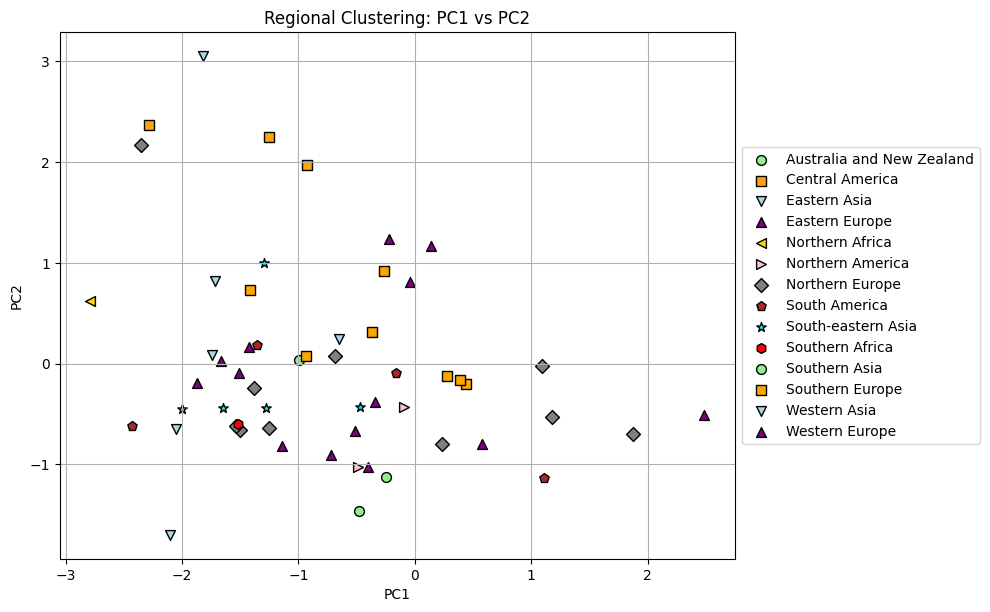

In [50]:
plot_region_clusters(target_df_hpi, 'PC1', 'PC2')

### Plot winner cluster based

In [51]:
def plot_clusters(df, x_col, y_col, cluster_col='cluster', country_col='Country', highlight_country='Paraguay'):
    """
    Plotea un scatter plot 2D coloreando los países según su cluster.
    Los países sin cluster (NaN) se muestran en gris con transparencia.
    """
    plt.figure(figsize=(10, 6))

    # Colores para clusters definidos
    unique_clusters = sorted(df[cluster_col].dropna().unique())
    colors = ['lightgreen', 'orange', 'lightblue', 'purple', 'gold', 'pink', 'brown', 'cyan', 'red', 'olive']
    cluster_color_map = {cluster: colors[i % len(colors)] for i, cluster in enumerate(unique_clusters)}

    # Graficar países con cluster definido
    for cluster in unique_clusters:
        mask = df[cluster_col] == cluster
        highlight_mask = mask & (df[country_col] == highlight_country)
        normal_mask = mask & (df[country_col] != highlight_country)

        # Otros países
        plt.scatter(df.loc[normal_mask, x_col], df.loc[normal_mask, y_col],
                    s=50, c=cluster_color_map[cluster], marker='o',
                    edgecolor='black', label=f'Cluster {int(cluster)}')

        # Paraguay destacado
        if highlight_mask.any():
            plt.scatter(df.loc[highlight_mask, x_col], df.loc[highlight_mask, y_col],
                        s=100, c=cluster_color_map[cluster], marker='X',
                        edgecolor='black', label=f'{highlight_country} (Cluster {int(cluster)})')

    # Graficar países sin cluster
    no_cluster_mask = df[cluster_col].isna()
    if no_cluster_mask.any():
        plt.scatter(df.loc[no_cluster_mask, x_col], df.loc[no_cluster_mask, y_col],
                    s=50, c='gray', alpha=0.5, marker='o',
                    edgecolor='black', label='Sin cluster')

    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.legend(scatterpoints=1, loc='center left', bbox_to_anchor=(1, 0.5))
    plt.grid(True)
    plt.tight_layout()
    plt.title(f'Cluster Mapping: {x_col} vs {y_col}')
    plt.show()

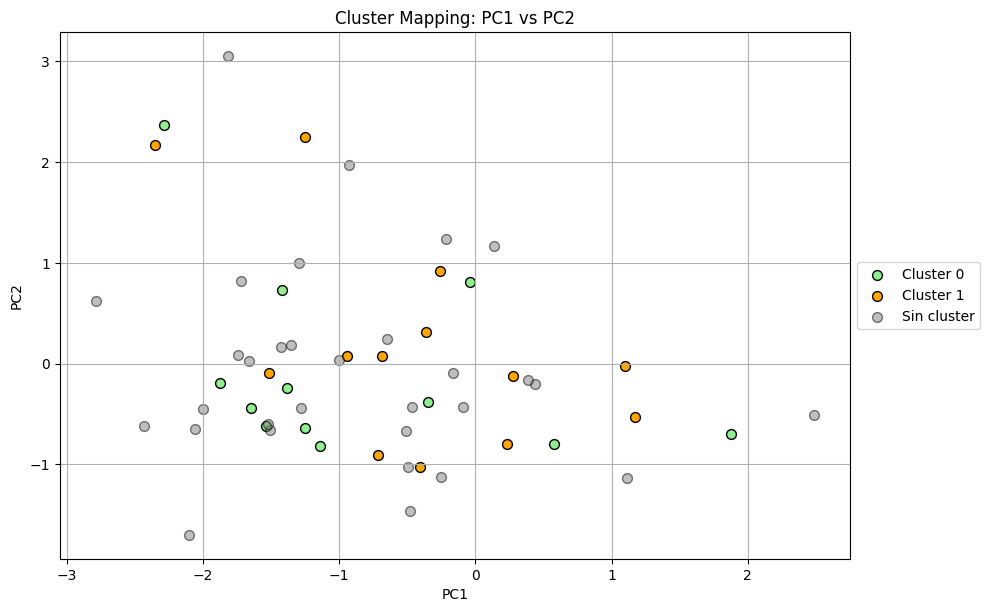

In [52]:
plot_clusters(target_df_hpi, 'PC1', 'PC2')